# softmax 处理多回归问题

- 观察公式可以得知——sigmoid 就是 softmax 在两种情况下的特例
- $p_k = \frac{e^{z_k}}{e^{z_0} + e^{z_1} + ... + e^{z_n}}$

In [45]:
import numpy as np
import torch
from PIL import Image
from torch import nn

IMAGES_PATH = "datas/QuickDraw"

torch.set_num_threads(1)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
device=torch.device("cpu")

In [46]:
def load_doodles(path):
    # 大图由 100 行 15 列、共 1500 张 28×28 的涂鸦拼成，先把它切回一张张涂鸦
    grid = np.array(Image.open(path))
    grid_reshape = grid.reshape(100, 28, 15, 28).swapaxes(1, 2).reshape(1500, 28, 28)
    # 归一化，这里的最大值其实就是255，最小值0
    mins = grid_reshape.min(axis=(1, 2), keepdims=True)
    maxs = grid_reshape.max(axis=(1, 2), keepdims=True)
    # 归一化 + 反相
    images_normalized = 1 - (grid_reshape - mins) / (maxs - mins)

    return torch.tensor(images_normalized, dtype=torch.float32, device=device)
# 1500张图片，每张大小 28*28
names = ["apple", "Eiffel Tower", "car", "lollipop", "T-shirt"]
files = ["apples", "eiffel-towers", "cars", "lollipops", "t-shirts"]
imgs = torch.cat([load_doodles(f"{IMAGES_PATH}/{file}.png") for file in files]).to(device)
# 标签 0～4 依次对应 names 中的 5 个类别，每类 1500 张
labels = torch.arange(5).repeat_interleave(1500).to(device)
print("特征 x：", tuple(imgs.shape), "标签 y：", tuple(labels.shape))
print("第 0、1500、3000、4500、6000 张涂鸦的标签：", labels[::1500].tolist())

特征 x： (7500, 28, 28) 标签 y： (7500,)
第 0、1500、3000、4500、6000 张涂鸦的标签： [0, 1, 2, 3, 4]


In [47]:
# 生成一个 0～6999 的随机序列，打乱数据
order = torch.randperm(7500, generator=torch.Generator().manual_seed(42)).to(device)

imgs = imgs.reshape(imgs.shape[0],imgs.shape[1] * imgs.shape[2])

train_ids = order[:4500]
test_id = order[4500: 6000]
val_ids = order[6000:]

x_train, y_train = imgs[train_ids], labels[train_ids]
x_test, y_test = imgs[test_id], labels[test_id]
x_val, y_test = imgs[val_ids], labels[val_ids]

In [48]:
# 参数初始化（权重，偏置，损失函数，优化器）
weights = torch.zeros(784, 5, requires_grad=True, device=device)
bias = torch.zeros(5, requires_grad=True,device=device)

print(weights.shape, bias.shape, x_train.shape)
logits = x_train @ weights + bias
print(logits.shape)

torch.Size([784, 5]) torch.Size([5]) torch.Size([4500, 784])
torch.Size([4500, 5])


In [49]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD([weights, bias], lr=0.2)

num_steps=500
train_losses, val_losses = [], []
for step in range(num_steps):
    # 计算结果
    logits = x_train @ weights + bias

    # 误差
    train_loss = loss_fn(logits, y_train)
    with torch.no_grad():
        val_logits = x_val @ weights + bias
        val_loss = loss_fn(val_logits, y_test)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if step % 100 == 0:
        print(f"训练集误差{train_loss}, 验证集误差{val_loss}")

    # 梯度下降
    optimizer.zero_grad()# 清空梯度
    train_loss.backward()# 计算梯度
    optimizer.step()# 梯度下降

训练集误差1.6094379425048828, 验证集误差1.6094378232955933
训练集误差0.16899093985557556, 验证集误差0.18381033837795258
训练集误差0.13950197398662567, 验证集误差0.16664837300777435
训练集误差0.1248493641614914, 验证集误差0.16125749051570892
训练集误差0.11504912376403809, 验证集误差0.15908314287662506


In [50]:
with torch.no_grad():
    predictions = (x_test @ weights + bias).argmax(dim=1)
# 第 i 行第 j 列：真实类别是 i、被预测为 j 的涂鸦数量
matrix = torch.zeros(5, 5, dtype=torch.int64)
for true, predicted in zip(y_test, predictions):
    matrix[true, predicted] += 1
print("测试集的混淆矩阵（行是真实类别，列是预测类别）")
print(" " * 13 + "".join(f"{name:>13}" for name in names))
for name, row in zip(names, matrix.tolist()):
    print(f"{name:>13}" + "".join(f"{count:>13}" for count in row))

测试集的混淆矩阵（行是真实类别，列是预测类别）
                     apple Eiffel Tower          car     lollipop      T-shirt
        apple           71           42           60           64           51
 Eiffel Tower           65           65           72           55           70
          car           53           68           56           69           66
     lollipop           66           46           67           52           57
      T-shirt           54           63           51           55           62


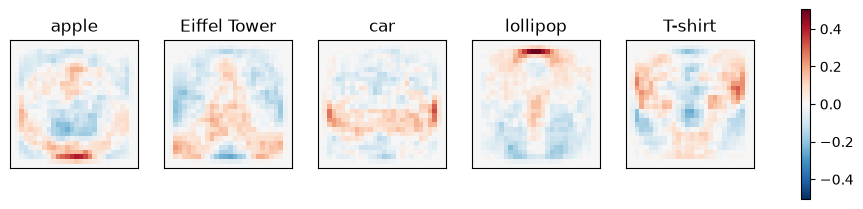

In [51]:
import matplotlib.pyplot as plt

# weights 的第 k 列是第 k 个类别的 784 个权重，按位置排回 28×28 画成权重图
# 红色支持这个类别，蓝色反对这个类别，颜色越深，权重的绝对值越大
w = weights.detach()
limit = w.abs().max().item()
fig, axes = plt.subplots(1, 5, figsize=(12, 2.9))
for k, ax in enumerate(axes):
    shown = ax.imshow(w[:, k].reshape(28, 28), cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(names[k])
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(shown, ax=axes.tolist(), shrink=0.85)
plt.show()